# Sephora Skincare Reviews: Customer Satisfaction and Recommendation Behaviour
**YuvaIntern - Data Science with Python Analyst Internship, Week 1** | Mohammed Anas

This notebook reproduces every number in the Week 1 report. It is an *exploratory, descriptive* analysis: no machine-learning, sentiment or predictive model is built, and associations are not interpreted as causes.

**Data:** Kaggle "Sephora Products and Skincare Reviews" (Inky, 2023) - download it yourself from Kaggle (check its licence) and place the six CSV files in a `data/` folder at the repository root: `reviews_0-250.csv`, `reviews_250-500_1.csv`, `reviews_500-750_1.csv`, `reviews_750-1250_1.csv`, `reviews_1250-end.csv`, `product_info.csv`. The original files are only read, never modified.

**Run:** open this notebook from the `code/` folder (or the repository root) and run all cells. Needs roughly 6-8 GB RAM; on Colab use a high-RAM runtime.

In [1]:
import glob, json, os, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
pd.set_option('display.width', 140); pd.set_option('display.max_columns', 30)

ROOT = Path.cwd().parent if Path.cwd().name == 'code' else Path.cwd()
DATA = ROOT / 'data'
review_files = sorted(glob.glob(str(DATA / '*reviews_*.csv')))
prod = pd.read_csv(DATA / 'product_info.csv')
print('review files found:', len(review_files)); print('product_info:', prod.shape)

review files found: 5
product_info: (8494, 27)


## 1. Inspect all files, combine safely, check duplicates and missing values

In [2]:
rows, hashes, idx, miss = [], [], [], pd.Series(dtype='int64')
keep = ['author_id','rating','is_recommended','helpfulness','total_feedback_count','submission_time','skin_tone','eye_color','skin_type','hair_color','product_id','product_name','brand_name','price_usd']
parts = []
for f in review_files:
    d = pd.read_csv(f, low_memory=False)
    rows.append((os.path.basename(f), len(d), d.shape[1], int(d['Unnamed: 0'].min()), int(d['Unnamed: 0'].max())))
    idx.append(d['Unnamed: 0'].to_numpy())
    hashes.append(pd.util.hash_pandas_object(d.drop(columns='Unnamed: 0'), index=False).to_numpy())  # ignore row counter
    miss = miss.add(d.isnull().sum(), fill_value=0)
    parts.append(d[keep]); del d
df = pd.concat(parts, ignore_index=True); del parts
N = len(df)
print(pd.DataFrame(rows, columns=['file','rows','columns','row_counter_min','row_counter_max']).to_string(index=False))
print(f'\nCombined review rows: {N:,}')
print('Row counter ("Unnamed: 0") values repeated across files:', f"{pd.Series(np.concatenate(idx)).duplicated().sum():,}", '-> not a unique ID, ignored')
print('Exact duplicate rows (ignoring row counter):', pd.Series(np.concatenate(hashes)).duplicated().sum(), 'kept; ~0.02% of data')
print('Products:', f'{df.product_id.nunique():,}', '| brands:', df.brand_name.nunique(), '| distinct author_ids:', f'{df.author_id.nunique():,}')
print('Review product_ids missing from product_info.csv:', (~pd.Series(df.product_id.unique()).isin(prod.product_id)).sum())
m = miss.drop('Unnamed: 0'); m = m[m > 0].sort_values(ascending=False)
pd.DataFrame({'missing': m.astype(int), 'percent': (100*m/N).round(1)})

                  file   rows  columns  row_counter_min  row_counter_max
     reviews_0-250.csv 602130       19                0           602129
  reviews_1250-end.csv  49977       19                0            49976
 reviews_250-500_1.csv 206725       19                0           206724
 reviews_500-750_1.csv 116262       19                0           116261
reviews_750-1250_1.csv 119317       19                0           119316

Combined review rows: 1,094,411
Row counter ("Unnamed: 0") values repeated across files: 492,281 -> not a unique ID, ignored
Exact duplicate rows (ignoring row counter): 224 kept; ~0.02% of data


Products: 2,351 | brands: 142 | distinct author_ids: 503,216
Review product_ids missing from product_info.csv: 0


,missing,percent
helpfulness,561592,51.3
review_title,310654,28.4
hair_color,226768,20.7
eye_color,209628,19.2
skin_tone,170539,15.6
is_recommended,167988,15.3
skin_type,111557,10.2
review_text,1444,0.1


## 2. Validate the initial 1,000-row sample (first 1,000 rows of `reviews_0-250.csv`)

In [3]:
first = [f for f in review_files if 'reviews_0-250' in f][0]
s = pd.read_csv(first, nrows=1000, low_memory=False)
tab = s.groupby('rating').agg(reviews=('rating','size'), recommended=('is_recommended','sum'), rate=('is_recommended','mean'))
tab['rate_%'] = (tab.rate*100).round(2)
print(tab[['reviews','recommended','rate_%']]); print(s.brand_name.value_counts().to_dict(), '| mean rating by brand:', s.groupby('brand_name').rating.mean().round(3).to_dict())
# verification against the previously reported results
assert s.rating.value_counts().sort_index().tolist() == [85, 83, 84, 144, 604]
assert tab['rate_%'].tolist() == [0.0, 3.61, 27.38, 93.75, 100.0]
assert s.brand_name.value_counts().to_dict() == {'LANEIGE': 999, 'NUDESTIX': 1}
print('\nInitial-sample results reproduced exactly.')

        reviews  recommended  rate_%
rating                              
1            85          0.0    0.00
2            83          3.0    3.61
3            84         23.0   27.38
4           144        135.0   93.75
5           604        604.0  100.00
{'LANEIGE': 999, 'NUDESTIX': 1} | mean rating by brand: {'LANEIGE': 4.098, 'NUDESTIX': 5.0}

Initial-sample results reproduced exactly.


## 3. Full dataset: rating distribution

        reviews  percent
rating                  
1         61223     5.59
2         53032     4.85
3         81816     7.48
4        199389    18.22
5        698951    63.87



4-5 stars: 898,340 (82.08%) | 1-2 stars: 114,255 (10.44%) | mean rating: 4.2992


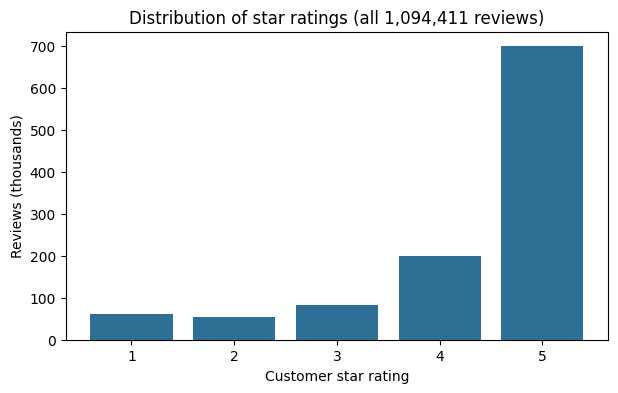

In [4]:
rc = df.rating.value_counts().sort_index()
dist = pd.DataFrame({'reviews': rc, 'percent': (100*rc/N).round(2)}); print(dist)
print(f"\n4-5 stars: {rc[[4,5]].sum():,} ({100*rc[[4,5]].sum()/N:.2f}%) | 1-2 stars: {rc[[1,2]].sum():,} ({100*rc[[1,2]].sum()/N:.2f}%) | mean rating: {df.rating.mean():.4f}")
fig, ax = plt.subplots(figsize=(7,4)); ax.bar(rc.index, rc.values/1000, color='#2E6F95')
ax.set_xlabel('Customer star rating'); ax.set_ylabel('Reviews (thousands)'); ax.set_title(f'Distribution of star ratings (all {N:,} reviews)'); plt.show()

## 4. Recommendation behaviour and its link with star rating
`is_recommended` is missing for some reviews; they are shown separately and excluded from recommendation-rate denominators (nothing is imputed).

recommended: 778160 | not recommended: 148263 | missing: 167988
share of ALL reviews that recommend: 71.10% | rate among recorded decisions: 84.00%
        all_reviews  with_decision  recommended  rate_%
rating                                                 
1             61223          52493        406.0    0.77
2             53032          45262       1660.0    3.67
3             81816          71395      25459.0   35.66
4            199389         170192     164351.0   96.57
5            698951         587081     586284.0   99.86



chi-square = 741,794 (p < 0.001) | Spearman rho = 0.716  -> strong ASSOCIATION; with >900,000 rows the effect size matters more than the p-value


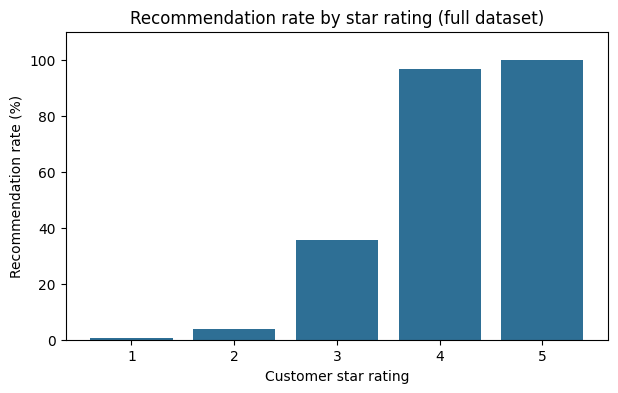

In [5]:
rec = df.is_recommended
print('recommended:', int((rec==1).sum()), '| not recommended:', int((rec==0).sum()), '| missing:', int(rec.isna().sum()))
print(f'share of ALL reviews that recommend: {100*(rec==1).sum()/N:.2f}% | rate among recorded decisions: {100*(rec==1).sum()/rec.notna().sum():.2f}%')
g = df.groupby('rating').agg(all_reviews=('is_recommended','size'), with_decision=('is_recommended','count'), recommended=('is_recommended','sum'), rate=('is_recommended','mean'))
g['rate_%'] = (g.rate*100).round(2); print(g[['all_reviews','with_decision','recommended','rate_%']])
k = df.dropna(subset=['is_recommended'])
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(k.rating, k.is_recommended))
rho = k.rating.corr(k.is_recommended, method='spearman')
print(f'\nchi-square = {chi2:,.0f} (p < 0.001) | Spearman rho = {rho:.3f}  -> strong ASSOCIATION; with >900,000 rows the effect size matters more than the p-value')
fig, ax = plt.subplots(figsize=(7,4)); ax.bar(g.index, g['rate_%'], color='#2E6F95'); ax.set_ylim(0,110)
ax.set_xlabel('Customer star rating'); ax.set_ylabel('Recommendation rate (%)'); ax.set_title('Recommendation rate by star rating (full dataset)'); plt.show()
assert g['rate_%'].tolist() == [0.77, 3.67, 35.66, 96.57, 99.86]

## 5. Brands and products (always with sample sizes)

In [6]:
b = df.groupby('brand_name').agg(reviews=('rating','size'), mean_rating=('rating','mean')).sort_values('reviews', ascending=False)
print(b.head(10).round(3))
big = b[b.reviews >= 1000].sort_values('mean_rating'); print(f'\nbrands with >=1,000 reviews: {len(big)}; lowest mean {big.mean_rating.iloc[0]:.2f} ({big.index[0]}), highest {big.mean_rating.iloc[-1]:.2f} ({big.index[-1]})')
print('LANEIGE:', b.loc['LANEIGE'].round(3).to_dict(), '| NUDESTIX:', b.loc['NUDESTIX'].round(3).to_dict(), '  <- sample had 999 and 1 reviews')
pr = df.groupby(['product_name','brand_name']).rating.agg(['size','mean']).reset_index()
print(f"\nproducts with reviews: {len(pr):,}; median reviews per product: {pr['size'].median():.0f}; max: {pr['size'].max():,}")
big_p = pr[pr['size'] >= 500].sort_values('mean'); print(f'\nproducts with >=500 reviews: {len(big_p)}'); print('lowest rated:'); print(big_p.head(5).round(3).to_string(index=False)); print('highest rated:'); print(big_p.tail(5).round(3).to_string(index=False))

                     reviews  mean_rating
brand_name                               
CLINIQUE               49029        4.250
Tatcha                 46770        4.241
Drunk Elephant         42395        4.085
fresh                  40886        4.377
The Ordinary           35934        4.212
Glow Recipe            31490        4.315
Youth To The People    29154        4.282
Origins                29063        4.360
Peter Thomas Roth      28846        4.316
LANEIGE                27519        4.373

brands with >=1,000 reviews: 95; lowest mean 3.66 (Topicals), highest 4.74 (DAMDAM)
LANEIGE: {'reviews': 27519.0, 'mean_rating': 4.373} | NUDESTIX: {'reviews': 381.0, 'mean_rating': 4.129}   <- sample had 999 and 1 reviews



products with reviews: 2,338; median reviews per product: 166; max: 16,138

products with >=500 reviews: 576
lowest rated:
                              product_name         brand_name  size  mean
Clean Cleansing & Gentle Exfoliating Wipes SEPHORA COLLECTION   524 2.563
               Vitamin C Brightening Cream     The INKEY List   518 3.031
                Focuspot Micro Tip Patches          Dr. Jart+   579 3.041
                    Clean Lip Balm & Scrub SEPHORA COLLECTION  1084 3.252
 Umbra Tinte Physical Daily Defense SPF 30     Drunk Elephant   845 3.298
highest rated:
                                                       product_name   brand_name  size  mean
                                       Daily Milkfoliant Exfoliator  Dermalogica   561 4.790
                       Floral Recovery Overnight Mask with Squalane        fresh  1128 4.797
             Truth Barrier Booster Orange Ferment Vitamin C Essence OLEHENRIKSEN   602 4.814
                                             

## 6. Price and customer characteristics

In [7]:
print(prod.price_usd.describe().round(2).to_dict())
dm = df[['product_id','rating']].merge(prod[['product_id','price_usd']].rename(columns={'price_usd':'p'}), on='product_id', how='left')
dm['price_band'] = pd.cut(dm.p, [0,25,50,100,1e9], labels=['<=25','25-50','50-100','>100'])
print(dm.groupby('price_band', observed=True).rating.agg(['size','mean']).round(3))
print('Spearman(price, rating) at review level:', round(dm[['p','rating']].corr(method='spearman').iloc[0,1], 3))
for c in ['skin_type','skin_tone']:
    print(); print(df.groupby(c).rating.agg(['size','mean']).sort_values('size', ascending=False).head(8).round(3))

{'count': 8494.0, 'mean': 51.66, 'std': 53.67, 'min': 3.0, '25%': 25.0, '50%': 35.0, '75%': 58.0, 'max': 1900.0}
              size   mean
price_band               
<=25        277686  4.263
25-50       437229  4.304
50-100      319904  4.329
>100         59592  4.267


Spearman(price, rating) at review level: 0.008

               size   mean
skin_type                 
combination  544513  4.309
dry          185937  4.291
normal       131910  4.282
oily         120494  4.271

               size   mean
skin_tone                 
light        266418  4.301
fair         208034  4.274
lightMedium  196541  4.319
medium        70486  4.331
mediumTan     62456  4.282
fairLight     56228  4.255
tan           33678  4.284
deep          20601  4.256


## 7. Complaint themes in low-rated reviews (keyword matching)
Keyword groups are **not** a validated sentiment model: they cannot detect negation or context, and groups overlap. Counts for 1-2 star reviews are compared with *all* 5-star reviews. The text is read in chunks by `themes_full.py` (about a few minutes), which writes the results into `results.json`.

In [8]:
import subprocess, sys
if not (ROOT/'code'/'results.json').exists():
    subprocess.run([sys.executable, str(ROOT/'code'/'analysis.py')], check=True)
out = subprocess.run([sys.executable, str(ROOT/'code'/'themes_full.py')], capture_output=True, text=True, check=True); print(out.stdout)

1-2 star reviews with text: 114061 | 5-star reviews with text: 697943
breakout / acne                    low-rated  21.9%   5-star  16.2%
irritation / burning / rash        low-rated  14.0%   5-star  11.6%
dryness / oiliness / heavy feel    low-rated  32.5%   5-star  34.5%
no visible effect                  low-rated  12.8%   5-star   0.5%
smell / fragrance                  low-rated  21.6%   5-star  22.5%
price / value                      low-rated  14.7%   5-star  11.3%
packaging / leaking / pump         low-rated  12.6%   5-star   5.9%
pilling / flaking / residue        low-rated   6.2%   5-star   4.1%



## 8. Final consistency check against `results.json` and the report

In [9]:
R = json.load(open(ROOT/'code'/'results.json'))
assert N == R['total_rows'] == 1094411 and df.product_id.nunique() == R['unique_products'] == 2351 and df.brand_name.nunique() == R['unique_brands'] == 142
assert rc.to_dict() == {int(a): v for a, v in R['rating_counts'].items()}
assert (int((rec==1).sum()), int((rec==0).sum()), int(rec.isna().sum())) == (778160, 148263, 167988)
assert abs(rho - R['spearman_rating_rec']) < 1e-9 and abs(chi2 - R['chi2'][0]) < 1
print('All notebook results agree with results.json and the figures reported in the Word report.')

All notebook results agree with results.json and the figures reported in the Word report.
